# 04: A Conventional Baseline

The first three notebooks answered the project's question with a Bayesian hierarchical model. This
one does something deliberately ordinary: predict whether a driver finishes on the podium, using
gradient boosting and the standard supervised-learning workflow.

It's here for two reasons.

**As a contrast.** A predictive model treats driver and car as one inseparable lump, it learns that
Red Bull entries finish well, without ever asking how much of that is the car. Setting it beside the
decomposition shows what the harder approach buys.

**As a competency check.** Feature engineering, feature selection, class imbalance and model
comparison are the bread and butter of applied ML, and the decomposition doesn't exercise any of
them.

It's deliberately not the centrepiece, so it gets a careful workflow rather than an exhaustive one, 
no hyperparameter search, no ensembling.

**Contents:**
1. Race results data.
2. What the result fields actually mean.
3. Defining the target.
4. Feature engineering.
5. Leakage check.
6. Feature selection, filter, wrapper, embedded.
7. Class imbalance.
8. Model comparison.
9. Quantified takeaways.

## Race results data

Qualifying pace came from lap timing. Race outcomes need something else: who started where, who
finished where, and how many points they scored.

[TracingInsights/RaceData](https://github.com/TracingInsights/RaceData) mirrors the Ergast/F1DB
dataset, 20 tables covering 1950 to the present, CC0 licensed. Four of them matter here: `races`,
`results`, `drivers` and `constructors`.

In [2]:
import io
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

archive = requests.get(
    'https://raw.githubusercontent.com/TracingInsights/RaceData/main/data.zip', timeout=60
)
with zipfile.ZipFile(io.BytesIO(archive.content)) as z:
    tables = {name: pd.read_csv(z.open(f'{name}.csv'))
              for name in ['races', 'results', 'drivers', 'constructors']}

for name, table in tables.items():
    print(f'{name:14s} {table.shape}')

races          (1171, 18)
results        (27480, 18)
drivers        (865, 9)
constructors   (214, 5)


In [3]:
races = tables['races'][tables['races']['year'].between(2018, 2025)]

race_results = (
    tables['results']
    .merge(races[['raceId', 'year', 'round', 'name', 'date']], on='raceId')
    .merge(tables['drivers'][['driverId', 'code']], on='driverId')
    .merge(tables['constructors'][['constructorId', 'name']].rename(
        columns={'name': 'constructor'}), on='constructorId')
)

print('rows:', len(race_results))
print('races:', race_results['raceId'].nunique())
print('seasons:', sorted(race_results['year'].unique()))
race_results[['year', 'round', 'name', 'code', 'constructor',
              'grid', 'position', 'positionText', 'positionOrder', 'points']].head()

rows: 3458
races: 173
seasons: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


,year,round,name,code,constructor,grid,position,positionText,positionOrder,points
0,2018,1,Australian Grand Prix,VET,Ferrari,3,1,1,1,25.0
1,2018,1,Australian Grand Prix,HAM,Mercedes,1,2,2,2,18.0
2,2018,1,Australian Grand Prix,RAI,Ferrari,2,3,3,3,15.0
3,2018,1,Australian Grand Prix,RIC,Red Bull,8,4,4,4,12.0
4,2018,1,Australian Grand Prix,ALO,McLaren,10,5,5,5,10.0


## What the result fields actually mean

Before defining anything, two columns need checking, because both have traps.

`positionOrder` ranks every entry including retirements, so a driver who stopped on lap 3 still gets
a number placing them behind the finishers. Ranking alone would treat that as a legitimate result.
`positionText` separates them: a number means classified in that place, `R` means retired.

`grid` should be the starting slot, but it carries codes for cases that aren't a normal start.

In [4]:
print('positionText values:')
print(race_results['positionText'].value_counts().head(12))
print()
print('grid values that are not a starting slot:')
print(race_results.loc[~race_results['grid'].astype(str).str.isdigit()
                       | (race_results['grid'].astype(str) == '0'),
                       'grid'].value_counts())

positionText values:
positionText
R     425
2     173
1     173
4     173
5     173
6     173
3     173
7     173
8     173
10    173
9     173
12    173
Name: count, dtype: int64

grid values that are not a starting slot:
grid
0     70
\N    20
Name: count, dtype: int64


Every classified position appears exactly 173 times (once per race) so the classification is
complete and consistent. Alongside those sit **425 retirements** marked `R`.

The grid column contains two values that need resolving before it can be converted to numbers:
**70 rows with `0`**, which is how a pit-lane start is recorded, and **20 rows with `\N`**, which is
the dataset's missing marker. What those 20 actually are decides whether they can be used.

In [5]:
missing_grid = race_results[race_results['grid'].astype(str) == '\\N']
print('rows with no grid position:', len(missing_grid))
print(missing_grid[['year', 'name', 'code', 'constructor',
                    'positionText', 'laps', 'points']].head(10).to_string(index=False))
print()
print('laps completed by these entries:', sorted(missing_grid['laps'].unique()))

rows with no grid position: 20
 year             name code  constructor positionText  laps  points
 2025 Qatar Grand Prix  VER     Red Bull            1    57    25.0
 2025 Qatar Grand Prix  PIA      McLaren            2    57    18.0
 2025 Qatar Grand Prix  SAI     Williams            3    57    15.0
 2025 Qatar Grand Prix  NOR      McLaren            4    57    12.0
 2025 Qatar Grand Prix  ANT     Mercedes            5    57    10.0
 2025 Qatar Grand Prix  RUS     Mercedes            6    57     8.0
 2025 Qatar Grand Prix  ALO Aston Martin            7    57     6.0
 2025 Qatar Grand Prix  LEC      Ferrari            8    57     4.0
 2025 Qatar Grand Prix  LAW   RB F1 Team            9    57     2.0
 2025 Qatar Grand Prix  TSU     Red Bull           10    57     1.0

laps completed by these entries: [np.int64(6), np.int64(41), np.int64(55), np.int64(56), np.int64(57)]


In [6]:
pit_lane = race_results[race_results['grid'].astype(str) == '0']
print('pit-lane starts:', len(pit_lane))
print('  reached the podium:', (pit_lane['positionText'].isin(['1', '2', '3'])).sum())
print('  median finish:', pit_lane['positionOrder'].median())
print()
print('for comparison, drivers starting from the back half of the grid:')
grid_numeric = pd.to_numeric(race_results['grid'], errors='coerce')
back = race_results[grid_numeric >= 15]
print('  median finish:', back['positionOrder'].median())

pit-lane starts: 70
  reached the podium: 0
  median finish: 15.0

for comparison, drivers starting from the back half of the grid:
  median finish: 15.0


### Both oddities resolved

**The 20 missing-grid rows are the entire 2025 Qatar field.** Verstappen won it, everyone completed
57 laps, so these aren't non-starters, the grid data is simply absent for that one race. Since grid
position is the strongest predictor available, a race without it can't contribute. I drop those 20
rows and note the loss rather than trying to reconstruct the grid from qualifying, which would be
wrong wherever a penalty was applied.

**Pit-lane starts behave like back-of-grid starts.** All 70 of them, zero podiums, median finish
15th, identical to drivers starting 15th or worse. So they get encoded as one place behind the last
grid slot. Leaving them as `0` would tell the model they started ahead of pole, which is the opposite
of the truth.

## Defining the target

Podium means classified first, second or third. Retirements are excluded from that by construction:
`positionText` marks them `R`, so they can never satisfy the condition even though `positionOrder`
still ranks them.

In [7]:
races_data = race_results[race_results['grid'].astype(str) != '\\N'].copy()

grid = pd.to_numeric(races_data['grid'], errors='coerce')
last_slot = grid[grid > 0].max()
races_data['grid_position'] = grid.where(grid > 0, last_slot + 1)

races_data['podium'] = races_data['positionText'].isin(['1', '2', '3'])

print(f'rows: {len(races_data)} (dropped {len(race_results) - len(races_data)} from Qatar 2025)')
print(f'pit-lane starts encoded as grid position {int(last_slot + 1)}')
print()
print(f'podiums: {races_data["podium"].sum()} of {len(races_data)} '
      f'= {races_data["podium"].mean():.1%}')
print(f'implied negative:positive ratio = {(~races_data["podium"]).sum() / races_data["podium"].sum():.1f}:1')

rows: 3438 (dropped 20 from Qatar 2025)
pit-lane starts encoded as grid position 21

podiums: 516 of 3438 = 15.0%
implied negative:positive ratio = 5.7:1


**15.0% podiums, a 5.7:1 imbalance.** Enough to distort the usual metrics, which the evaluation
section deals with directly.

## Feature engineering

Every feature has to be knowable *before the race starts*. That rules out anything derived from the
result, and (less obviously) anything computed over the whole season, since that quietly includes
races that hadn't happened yet.

Five raw fields, each available on the grid:

- **`grid_position`**: where they start. Almost certainly the dominant predictor.
- **`constructor`**: the car.
- **`driver`**: who's driving.
- **`circuit`**: some tracks make overtaking nearly impossible, which changes how much starting
  position determines finishing position.
- **`round`**: where in the season we are.

And three engineered ones, each answering something the raw fields don't:

- **`points_before`**: championship points so far this season, excluding this race. A rough measure
  of how the season has gone.
- **`recent_form`**: average finishing position over the driver's previous three races. Points
  accumulate all year and lag badly; a driver whose car was upgraded last month looks the same by
  season total but very different by recent form.
- **`circuit_history`**: the driver's average finish at this circuit in previous seasons. Some
  drivers are repeatedly strong at particular tracks.

All three are cumulative, and all three are where leakage creeps in. Each gets shifted so the current
race is excluded, and the next section tests that the shifting actually worked.

In [8]:
def build_features(df):
    """Pre-race features only. Every cumulative column excludes the current race."""
    out = df.sort_values(['year', 'round']).copy()
    out['circuit'] = out['name']

    out['points_before'] = (out.groupby(['year', 'code'])['points'].cumsum()
                            - out['points'])

    out['recent_form'] = (out.groupby('code')['positionOrder']
                          .transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean()))

    out['circuit_history'] = (out.groupby(['code', 'circuit'])['positionOrder']
                              .transform(lambda s: s.shift(1).expanding().mean()))
    return out


features = build_features(races_data)

print(features[['year', 'round', 'code', 'grid_position', 'points_before',
                'recent_form', 'circuit_history', 'podium']].head(8).to_string(index=False))
print()
print('missing values (drivers with no history yet):')
print(features[['recent_form', 'circuit_history']].isna().sum())

 year  round code  grid_position  points_before  recent_form  circuit_history  podium
 2018      1  VET              3            0.0          NaN              NaN    True
 2018      1  HAM              1            0.0          NaN              NaN    True
 2018      1  RAI              2            0.0          NaN              NaN    True
 2018      1  RIC              8            0.0          NaN              NaN   False
 2018      1  ALO             10            0.0          NaN              NaN   False
 2018      1  VER              4            0.0          NaN              NaN   False
 2018      1  HUL              7            0.0          NaN              NaN   False
 2018      1  BOT             15            0.0          NaN              NaN   False

missing values (drivers with no history yet):
recent_form          43
circuit_history    1166
dtype: int64


`circuit_history` is missing for **1,166 rows, 34% of the data.** Drivers visit each circuit once a
season, so every first visit has none. That's a real weakness rather than a bug, and the ablation
step below tests whether the feature is useful despite this.

## Leakage check

The three engineered features are cumulative, which is exactly where leakage hides. Get the shift
wrong by one row and the model sees each race's own result before predicting it, producing
excellent scores that mean nothing.

Reading the code and convincing myself it looks right isn't enough. The test: **change a future race,
recompute everything, and confirm nothing before that race moved.** If any earlier row shifts, a
later result is feeding backwards.

In [9]:
tampered = races_data.copy()
target_race = (tampered['year'] == 2023) & (tampered['round'] == 20)
tampered.loc[target_race, 'points'] = 99
tampered.loc[target_race, 'positionOrder'] = 1

original = build_features(races_data)
after = build_features(tampered)

engineered = ['points_before', 'recent_form', 'circuit_history']
earlier = (original['year'] < 2023) | ((original['year'] == 2023) & (original['round'] < 20))

before_changed = (original.loc[earlier, engineered]
                  .compare(after.loc[earlier, engineered]))
later_changed = (original.loc[~earlier, engineered]
                 .compare(after.loc[~earlier, engineered]))

print(f'rows before the tampered race: {earlier.sum()}')
print(f'  of which changed: {len(before_changed)}   <- must be 0')
print()
print(f'rows after it: {(~earlier).sum()}')
print(f'  of which changed: {len(later_changed)}   <- should be > 0, or the test proves nothing')

assert len(before_changed) == 0, 'LEAKAGE: a future result changed an earlier feature'
assert len(later_changed) > 0, 'test is inert - tampering had no effect anywhere'
print()
print('passed: no future information reaches earlier rows')

rows before the tampered race: 2440
  of which changed: 0   <- must be 0

rows after it: 998
  of which changed: 88   <- should be > 0, or the test proves nothing

passed: no future information reaches earlier rows


Nothing before the tampered race moved, and 88 rows after it did, so the test was capable of failing. The
engineered features are safe to use.

## Feature selection

Three stages, each answering a different question. All three are worth running: they disagree
often enough that any one alone can mislead.

1. **Filter**: do any features carry the same information as each other? Cheap, model-free, and
   catches redundancy before it reaches a model that will happily split its attributions between two
   near-identical columns.
2. **Wrapper**: does adding the engineered features actually improve held-out predictions? This is
   the only stage that tests a feature *in the model it will be used in*, interactions included.
3. **Embedded**: once fitted, does the model genuinely rely on them, and in the direction that makes
   sense?

### Filter: what overlaps with what

For the numeric features, pairwise correlation. For the categorical ones, Cramér's V, the same idea
for categories, scaled 0 to 1, where 1 means knowing one tells you the other exactly.

In [10]:
from scipy.stats import chi2_contingency

numeric = ['grid_position', 'points_before', 'recent_form', 'circuit_history', 'round']
categorical = ['code', 'constructor', 'circuit']

print('numeric correlations:')
print(features[numeric].corr().round(2))
print()


def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = chi2_contingency(table)[0]
    n = table.values.sum()
    smaller = min(table.shape) - 1
    return np.sqrt(chi2 / (n * smaller)) if smaller > 0 else np.nan


print('Cramers V between categoricals:')
associations = pd.DataFrame(
    [[cramers_v(features[a], features[b]) for b in categorical] for a in categorical],
    index=categorical, columns=categorical,
)
print(associations.round(2))

numeric correlations:
                 grid_position  points_before  recent_form  circuit_history  \
grid_position             1.00          -0.50         0.61             0.37   
points_before            -0.50           1.00        -0.63            -0.39   
recent_form               0.61          -0.63         1.00             0.40   
circuit_history           0.37          -0.39         0.40             1.00   
round                     0.00           0.42         0.01            -0.01   

                 round  
grid_position     0.00  
points_before     0.42  
recent_form       0.01  
circuit_history  -0.01  
round             1.00  

Cramers V between categoricals:
             code  constructor  circuit
code         1.00         0.72     0.08
constructor  0.72         1.00     0.08
circuit      0.08         0.08     1.00


### Nothing is redundant enough to drop

The strongest association anywhere is **driver ↔ constructor at 0.72**, high, since drivers belong
to teams, but well short of duplication because drivers move between teams and teams change lineups.
Among the numeric features the peak is **`points_before` ↔ `recent_form` at −0.63**: related, as
expected, but one is cumulative over the season and the other covers three races. That difference is
the entire reason `recent_form` exists.

`circuit` is independent of everything (0.08), which is reassuring, it should be.

**`round` is the one that looks pointless.** It correlates 0.42 with `points_before` for purely
mechanical reasons and effectively zero with everything else. The filter can't tell whether that
makes it useless, only that it isn't duplicating anything. The wrapper can.

### Wrapper: do the engineered features improve the model?

Fit on one set of features, fit on another, compare held-out performance. Two decisions matter here.

**The split is chronological, not random.** Train on 2018–2023, test on 2024–2025. A random split
would scatter races from the same season across both sides, letting the model learn 2023's pecking
order from 2023 races and then predict 2023 races, which would look good and mean nothing, since the real task is
predicting a season you haven't seen. This is the same reasoning that governed the target metric in
notebook 01: respect the time ordering.

**PR-AUC is the headline metric, not accuracy.** At 15% positives, predicting "no podium" for
everyone scores 85% accuracy while being useless. Precision-recall AUC measures performance on the
rare class, which is the class anyone cares about.

In [11]:
from lightgbm import LGBMClassifier
from sklearn.metrics import average_precision_score, log_loss, precision_score, recall_score

RAW = ['grid_position', 'round', 'code', 'constructor', 'circuit']
ENGINEERED = ['points_before', 'recent_form', 'circuit_history']
CATEGORICAL = ['code', 'constructor', 'circuit']

model_frame = features.copy()
for column in CATEGORICAL:
    model_frame[column] = model_frame[column].astype('category')

train = model_frame[model_frame['year'] <= 2023]
test = model_frame[model_frame['year'] >= 2024]
print(f'train: {len(train)} rows (2018-2023) | test: {len(test)} rows (2024-2025)')
print(f'podium rate  train {train["podium"].mean():.1%} | test {test["podium"].mean():.1%}')
print()


def evaluate(columns, label, **kwargs):
    model = LGBMClassifier(random_state=0, verbose=-1, **kwargs)
    model.fit(train[columns], train['podium'])
    probability = model.predict_proba(test[columns])[:, 1]
    prediction = model.predict(test[columns])
    return {
        'features': label,
        'pr_auc': average_precision_score(test['podium'], probability),
        'log_loss': log_loss(test['podium'], probability),
        'precision': precision_score(test['podium'], prediction, zero_division=0),
        'recall': recall_score(test['podium'], prediction, zero_division=0),
    }, model


ablation = pd.DataFrame([
    evaluate(RAW, 'raw only')[0],
    evaluate(RAW + ENGINEERED, 'raw + engineered')[0],
    evaluate([c for c in RAW if c != 'round'] + ENGINEERED, 'without round')[0],
    evaluate([c for c in RAW + ENGINEERED if c != 'circuit_history'], 'without circuit_history')[0],
]).set_index('features')

ablation.round(4)

train: 2500 rows (2018-2023) | test: 938 rows (2024-2025)
podium rate  train 15.0% | test 15.0%



,pr_auc,log_loss,precision,recall
features,,,,
raw only,0.6456,0.2782,0.6429,0.4468
raw + engineered,0.6310,0.2849,0.6279,0.5745
without round,0.6284,0.2823,0.6260,0.5816
without circuit_history,0.6590,0.2603,0.6780,0.5674


### One engineered feature helped, one hurt

Adding all three engineered features made the model **worse**, PR-AUC fell from 0.6456 to 0.6310.
Dropping just `circuit_history` produced the best result on every metric at once:

| | raw only | best set |
|---|---|---|
| PR-AUC | 0.6456 | **0.6590** |
| log-loss | 0.2782 | **0.2603** |
| precision | 0.6429 | **0.6780** |
| recall | 0.4468 | **0.5674** |

So `points_before` and `recent_form` are useful, and `circuit_history` was reducing
performance, which is unsurprising for a feature absent a third of the time. Reasoning alone would not have settled this. Fitting the model both ways did.

The `without round` row above is confounded, since it still contains `circuit_history`. Testing
`round` properly means removing it from the winning set instead.

In [12]:
BEST = ['grid_position', 'round', 'code', 'constructor', 'circuit',
        'points_before', 'recent_form']

round_check = pd.DataFrame([
    evaluate(BEST, 'best set')[0],
    evaluate([c for c in BEST if c != 'round'], 'best set, no round')[0],
]).set_index('features')

round_check.round(4)

,pr_auc,log_loss,precision,recall
features,,,,
best set,0.6590,0.2603,0.6780,0.5674
"best set, no round",0.6314,0.2830,0.6429,0.5745


### The filter was wrong about `round`

Removing it costs 0.028 PR-AUC and worsens log-loss and precision. Yet it correlates with essentially
nothing on its own.

This is the difference between the two stages. Correlation measures a feature **in isolation**; a tree model
uses it in **interactions**, "late in the season, for a driver on this much points" is a different
statement from either part alone. A filter cannot detect this, so it can only be a first pass rather than the final decision.

**Final feature set:** grid position, round, driver, constructor, circuit, points before this race,
and recent form. Seven features, one dropped after testing.

### Embedded: what the model actually uses

SHAP attributes each prediction to the features that produced it, so it answers a different question
from the ablation: not "does removing this hurt?" but "what is the model doing with it?"

I use SHAP rather than LightGBM's built-in importance. That one counts how often a feature is
split on, which favours columns with many categories. `driver` has 43 levels and `circuit` around
30, so both would look important just for offering more places to split.

The check that matters: **grid position should dominate.** If something else does, the model has
found a shortcut rather than the actual mechanism, and I'd want to know why before trusting anything
else it says.

In [13]:
import warnings
import shap

metrics_best, model_best = evaluate(BEST, 'best set')

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    explainer = shap.TreeExplainer(model_best)
    shap_values = explainer.shap_values(test[BEST])

# shap returns one array, a list per class, or a 3D stack depending on version
if isinstance(shap_values, list):
    shap_values = shap_values[1]
elif shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]

importance = pd.Series(np.abs(shap_values).mean(axis=0), index=BEST).sort_values(ascending=False)
print('shap values shape:', shap_values.shape)
print()
print('mean |SHAP| - average contribution to a prediction:')
print(importance.round(4))

shap values shape: (938, 7)

mean |SHAP| - average contribution to a prediction:
grid_position    1.6389
points_before    0.8975
code             0.6946
recent_form      0.4246
constructor      0.3572
round            0.3227
circuit          0.2914
dtype: float64


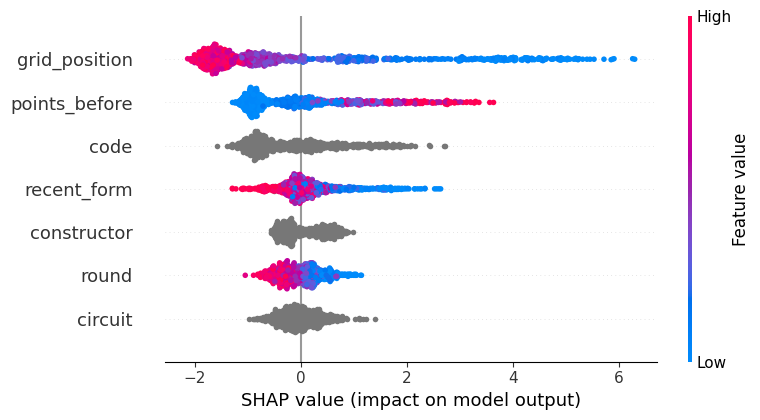

In [14]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    shap.summary_plot(shap_values, test[BEST], show=False)
plt.tight_layout()
plt.show()

### Grid position dominates, and the constructor barely registers

| feature | mean \|SHAP\| |
|---|---|
| grid_position | **1.639** |
| points_before | 0.898 |
| driver | 0.695 |
| recent_form | 0.425 |
| **constructor** | **0.357** |
| round | 0.323 |
| circuit | 0.291 |

Grid position contributes nearly twice as much as anything else, which is the sanity check passing:
the model found the actual mechanism rather than a shortcut.

The interesting part is **constructor sitting second from bottom, below driver.** Taken at face value
this contradicts notebook 03, where the car mattered about 2.8× more than the driver.

There is no contradiction. The reason explains why this project needed the harder approach.

**Grid position already contains the car.** A driver starts third because their car is quick and they
drove it well; those two facts arrive fused into a single number. Once the model knows the grid slot,
the constructor label adds almost nothing, because its information has already been absorbed. The
model isn't saying the car doesn't matter. It's saying the car doesn't matter *given that you already
know where the car qualified*.

That is precisely the trap a predictive model sets. It answers "who will finish on the podium?"
accurately while being structurally incapable of answering "how much of this is the car?", the
question that requires deliberately taking that fused number apart, which is what notebooks 01–03
spent their effort on.

## Class imbalance

At 15% positives, the default 0.5 decision threshold is close to arbitrary, and accuracy is
meaningless. There are two standard responses, and both are worth testing:

- **`scale_pos_weight`** tells LightGBM to weight the rare class more heavily during training.
- **Moving the threshold** leaves training alone and changes only the point at which a probability
  becomes a prediction.

PR-AUC is unaffected by the threshold (it summarises performance across all of them) so it stays
the metric for comparing models, while precision and recall show what a chosen threshold buys.

In [15]:
ratio = (~train['podium']).sum() / train['podium'].sum()

imbalance = pd.DataFrame([
    evaluate(BEST, 'default')[0],
    evaluate(BEST, f'scale_pos_weight={ratio:.1f}', scale_pos_weight=ratio)[0],
    evaluate(BEST, 'class_weight=balanced', class_weight='balanced')[0],
]).set_index('features')

print(f'negative:positive in training = {ratio:.1f}:1')
print()
imbalance.round(4)

negative:positive in training = 5.7:1



,pr_auc,log_loss,precision,recall
features,,,,
default,0.6590,0.2603,0.6780,0.5674
scale_pos_weight=5.7,0.6485,0.2779,0.6273,0.7163
class_weight=balanced,0.6572,0.2852,0.5954,0.7305


### Does reweighting just move the threshold?

PR-AUC barely shifts across the three (0.659 / 0.649 / 0.657) while precision and recall move in opposite directions. That pattern is what you'd see if reweighting weren't improving the model's ability to
*rank* drivers by podium likelihood, only relocating the decision boundary, something a threshold
does without retraining anything.

That's a hypothesis, not a finding. If it holds, tuning the threshold on the plain model should
reproduce the reweighted model's recall at equal or better precision.

In [16]:
probability = model_best.predict_proba(test[BEST])[:, 1]
target_recall = imbalance.loc['scale_pos_weight=5.7', 'recall']

sweep = []
for threshold in np.arange(0.05, 0.75, 0.01):
    prediction = probability >= threshold
    sweep.append({
        'threshold': threshold,
        'precision': precision_score(test['podium'], prediction, zero_division=0),
        'recall': recall_score(test['podium'], prediction, zero_division=0),
    })
sweep = pd.DataFrame(sweep)

matched = sweep.iloc[(sweep['recall'] - target_recall).abs().argmin()]
print(f'reweighted model : recall {target_recall:.4f}, '
      f'precision {imbalance.loc["scale_pos_weight=5.7", "precision"]:.4f}')
print(f'plain + threshold: recall {matched["recall"]:.4f}, '
      f'precision {matched["precision"]:.4f}  (threshold {matched["threshold"]:.2f})')

reweighted model : recall 0.7163, precision 0.6273
plain + threshold: recall 0.7163, precision 0.5976  (threshold 0.29)


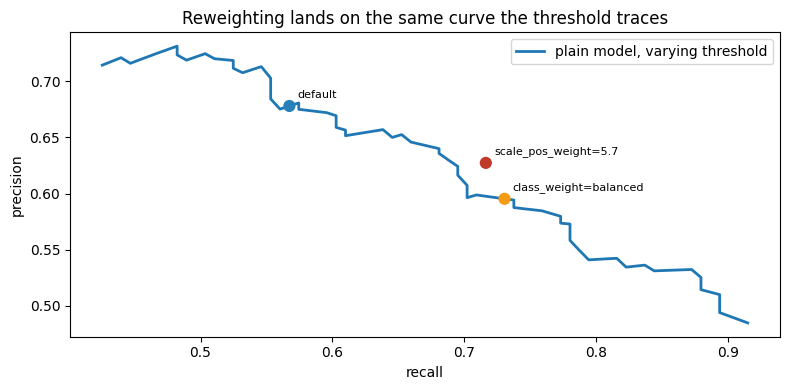

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sweep['recall'], sweep['precision'], lw=2, label='plain model, varying threshold')
ax.scatter(imbalance['recall'], imbalance['precision'], zorder=3, s=60,
           c=['#2980b9', '#c0392b', '#f39c12'])
for name, row in imbalance.iterrows():
    ax.annotate(name, (row['recall'], row['precision']),
                textcoords='offset points', xytext=(6, 6), fontsize=8)
ax.set_xlabel('recall')
ax.set_ylabel('precision')
ax.set_title('Reweighting lands on the same curve the threshold traces')
ax.legend()
plt.tight_layout()
plt.show()

### Not quite, reweighting does add something

| at recall 0.7163 | precision |
|---|---|
| reweighted model | **0.6273** |
| plain model at threshold 0.29 | 0.5976 |

My hypothesis was that reweighting would be a threshold move in disguise. It isn't: at matched recall
it holds **3 points more precision**. Yet its PR-AUC across all thresholds is slightly *lower* (0.6485
against 0.6590).

Both are true at once, and they aren't in tension. Weighting the rare class more heavily focuses the
model where positives live, which pays off in the high-recall region and costs a little elsewhere.
Averaged over every threshold (which is what PR-AUC does) the loss slightly outweighs the gain.

So the choice depends on what the model is for:

- **Ranking drivers by podium likelihood**, or picking a threshold later → the plain model, better
  PR-AUC and better calibrated.
- **Catching as many podium finishers as possible**, accepting false alarms → the reweighted model.

I keep the plain model as the baseline, since better overall ranking and a threshold left open is the
more useful default. It's worth stating that this ran the other way from what I expected.

## Model comparison

Gradient boosting is the default choice for tabular data, which is reason enough to check
whether it helps here. Logistic regression is the honest comparison: fast, standard,
and if it matches, the extra complexity isn't buying anything.

It needs slightly different handling, no native categorical support and no tolerance for missing
values, so categories get one-hot encoded and `recent_form` gets imputed. That's a fair fight rather
than a rigged one: each model gets the preprocessing it needs.

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUMERIC = ['grid_position', 'round', 'points_before', 'recent_form']

logistic = Pipeline([
    ('prepare', ColumnTransformer([
        ('numeric', Pipeline([('impute', SimpleImputer(strategy='median')),
                              ('scale', StandardScaler())]), NUMERIC),
        ('categorical', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL),
    ])),
    ('model', LogisticRegression(max_iter=2000, random_state=0)),
])

logistic.fit(train[BEST], train['podium'])
logistic_probability = logistic.predict_proba(test[BEST])[:, 1]
logistic_prediction = logistic.predict(test[BEST])

comparison = pd.DataFrame([
    {'model': 'LightGBM', **{k: v for k, v in metrics_best.items() if k != 'features'}},
    {'model': 'logistic regression',
     'pr_auc': average_precision_score(test['podium'], logistic_probability),
     'log_loss': log_loss(test['podium'], logistic_probability),
     'precision': precision_score(test['podium'], logistic_prediction, zero_division=0),
     'recall': recall_score(test['podium'], logistic_prediction, zero_division=0)},
]).set_index('model')

comparison.round(4)

,pr_auc,log_loss,precision,recall
model,,,,
LightGBM,0.6590,0.2603,0.6780,0.5674
logistic regression,0.6513,0.2380,0.6875,0.4681


### Gradient boosting doesn't earn its complexity

| | PR-AUC | log-loss | precision | recall |
|---|---|---|---|---|
| LightGBM | **0.6590** | 0.2603 | 0.6780 | **0.5674** |
| logistic regression | 0.6513 | **0.2380** | **0.6875** | 0.4681 |

A PR-AUC gap of 0.008 is nothing, and the linear model is **better calibrated**, a materially lower
log-loss means its probabilities are closer to being trustworthy as probabilities, which matters if
anyone wants to read "0.7" as a genuine 70%.

That result follows from what SHAP showed. Grid position carries most of the signal and relates to
podium probability in a simple, monotonic way: start further forward, finish further forward. There
isn't much non-linear structure for a tree ensemble to find, so it finds little.

Reporting this rather than quietly keeping the more impressive-sounding model is the point. **Trying
the simple baseline is what tells you whether the complex one is doing anything**, and here it is
barely doing anything at all.

I keep LightGBM as the saved baseline for its slightly better ranking and its native handling of
categories and missing values, but the honest headline is that the two are level.

## Saving the baseline

In [19]:
import json as json_module
import pickle

with open('/kaggle/working/baseline_model.pkl', 'wb') as handle:
    pickle.dump(model_best, handle)

baseline_metrics = {
    'features': BEST,
    'train_seasons': [2018, 2023],
    'test_seasons': [2024, 2025],
    'podium_rate': float(features['podium'].mean()),
    'lightgbm': {k: float(v) for k, v in metrics_best.items() if k != 'features'},
    'logistic_regression': {k: float(v) for k, v in
                            comparison.loc['logistic regression'].items()},
}
with open('/kaggle/working/baseline_metrics.json', 'w') as handle:
    json_module.dump(baseline_metrics, handle, indent=2)

print(json_module.dumps(baseline_metrics, indent=2))

{
  "features": [
    "grid_position",
    "round",
    "code",
    "constructor",
    "circuit",
    "points_before",
    "recent_form"
  ],
  "train_seasons": [
    2018,
    2023
  ],
  "test_seasons": [
    2024,
    2025
  ],
  "podium_rate": 0.15008726003490402,
  "lightgbm": {
    "pr_auc": 0.6590008310243493,
    "log_loss": 0.2603465389976103,
    "precision": 0.6779661016949152,
    "recall": 0.5673758865248227
  },
  "logistic_regression": {
    "pr_auc": 0.6513161211028509,
    "log_loss": 0.23797141840803926,
    "precision": 0.6875,
    "recall": 0.46808510638297873
  }
}


## Quantified takeaways

1. **One engineered feature helped and one hurt, and only the ablation could tell them apart.**
   Adding all three dropped PR-AUC from 0.6456 to 0.6310; dropping `circuit_history` alone lifted it
   to **0.6590**, the best result on every metric. A driver's history at a circuit sounds predictive,
   but it's missing for 34% of rows because drivers visit each track once a season. No amount of
   reasoning settled that, fitting it both ways did.

2. **The filter stage was wrong about `round`.** It correlates with essentially nothing, so a
   correlation-based cut would have removed it. Removing it costs **0.028 PR-AUC**, because trees use
   it in interactions rather than alone. Filters see features in isolation; only the wrapper sees
   them in the model they'll live in.

3. **Grid position accounts for nearly twice the contribution of anything else, and the constructor
   barely registers** (mean |SHAP| 1.64 against 0.36). That isn't a contradiction of notebook 03's
   finding that the car dominates: it's the same fact seen from the other side. **Grid position
   already contains the car**, so once it's known the constructor label adds almost nothing. A
   predictive model can be accurate and still be structurally unable to separate driver from car.

4. **Class reweighting isn't the threshold move I expected.** At matched recall it holds 3 points
   more precision than the plain model (0.6273 against 0.5976), while scoring slightly *worse* on
   PR-AUC across all thresholds (0.6485 against 0.6590). It genuinely helps in the high-recall
   region and costs a little everywhere else.

5. **Logistic regression matches gradient boosting**: PR-AUC 0.6513 against 0.6590, with a better
   log-loss (0.2380 against 0.2603) and better precision. The signal is dominated by one roughly
   monotonic feature, leaving little non-linear structure to exploit. Running the simple baseline is
   what revealed that the complex model was adding nothing.